**SAPIANS** · SCC5819 · MÓDULO 07 — ALE · MOLNAR, CAP. 20

# Diferenças locais mudam a pergunta feita à idade

O PDP movia a entrada em todas as fichas; o ALE compara bordas apenas nas janelas ocupadas pela entrada.

[README do módulo](../README.md) · [outline da aula](../lecture/outline.md) · [Colab](https://colab.research.google.com/github/wbendinelli/interpretable-ml-lectures/blob/main/modules/07-ale/notebooks/ale_walkthrough.ipynb)

---

**Objetivos.** Executar o método no modelo fixo do curso, conferir a fórmula e delimitar o que a medida permite concluir.

In [1]:
%pip install -q numpy pandas pyarrow scikit-learn xgboost matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import hashlib
import inspect
import itertools
import os
import pathlib
import subprocess
import sys
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import log_loss
from xgboost import XGBClassifier

RANDOM_STATE = 42
REPO = pathlib.Path(
    os.environ.get("INTERPRETABLE_ML_REPO", pathlib.Path.cwd())
).resolve()
while REPO != REPO.parent and not (REPO / "tools/README.md").exists():
    REPO = REPO.parent
if not (REPO / "tools/README.md").exists():
    REPO = pathlib.Path(tempfile.gettempdir()) / "interpretable-ml-lectures"
    if not REPO.exists():
        subprocess.run(
            [
                "git",
                "clone",
                "--depth",
                "1",
                "https://github.com/wbendinelli/interpretable-ml-lectures.git",
                str(REPO),
            ],
            check=True,
            capture_output=True,
        )
sys.path.insert(0, str(REPO / "tools"))
import sapians as SP
import srag_60_model as M
import srag_71_global_effects as G

# Tudo que é gerado fica fora da árvore de trabalho; só cópias explícitas são publicadas.
WORK = pathlib.Path(
    os.environ.get("GLOBAL_EFFECTS_WORK", tempfile.mkdtemp(prefix="global-effects-"))
)
os.chdir(WORK)
SP.aplicar(tema="global")
print("Perfil visual: SAPIANS Global / VITA | fonte:", SP.FONTE_ATUAL)

Perfil visual: SAPIANS Global / VITA | fonte: Satoshi


## §1 — Mesmo dado, mesmo preditor, pergunta global

A amostra Gold do módulo da base e a receita histórica são reutilizadas sem seleção ou balanceamento adicional. A ordem por identificador precede o sorteio; o alvo não orienta a escolha das fichas. O fundo integra as outras entradas. Painel e fundo são amostras de explicação do teste temporal, não novas partições para selecionar modelos.

In [3]:
path = REPO / "modules/00-dataset/gold/gold_covid_obito_sample.parquet"
gold = M.load_gold(path)
x, _, y = M.design_matrix(gold)
tr = (gold["split"] == "train").to_numpy()
te = (gold["split"] == "test").to_numpy()
model = XGBClassifier(**M.XGB_PARAMS).fit(x.loc[tr], y[tr])
model_bytes = bytes(model.get_booster().save_raw())


def prever(frame):
    return np.asarray(model.predict_proba(frame[list(M.FEATURES)])[:, 1], dtype=float)


teste = gold.loc[te].sort_values("gold_id").reset_index(drop=True)
# Sorteio independente do alvo, do erro e da magnitude dos efeitos.
painel = teste.sample(n=512, random_state=RANDOM_STATE).reset_index(drop=True)
fundo = painel.iloc[:256].copy()
xf = M.design_matrix(fundo)[0]
xp = M.design_matrix(painel)[0]
original_xf = xf.copy(deep=True)
print("SHA256 da amostra:", hashlib.sha256(path.read_bytes()).hexdigest())
print("SHA256 do preditor desta execução:", hashlib.sha256(model_bytes).hexdigest())
print("Semente:", SP.pt_int(RANDOM_STATE))
print("Treino até:", str(2022), "| validação:", str(2023), "| teste:", str(2024))
print(
    "Treino:",
    SP.pt_int(tr.sum()),
    "| validação:",
    SP.pt_int((gold["split"] == "val").sum()),
)
print("Teste completo:", SP.pt_int(te.sum()), "| óbitos:", SP.pt_int(y[te].sum()))
print(
    "Entradas:",
    SP.pt_int(len(M.FEATURES)),
    "| painel:",
    SP.pt_int(len(painel)),
    "| fundo:",
    SP.pt_int(len(fundo)),
)
print("Log loss do teste completo:", SP.pt(log_loss(y[te], prever(x.loc[te])), 6))
print("Previsão média no painel:", SP.pct(prever(xp).mean()))
print(
    "Versões:",
    "Python",
    sys.version.split()[0],
    "| numpy",
    np.__version__,
    "| pandas",
    pd.__version__,
)
print("Alvo não participa das curvas; teste já observado, análise exploratória.")

SHA256 da amostra: cb79c99338a5a7b3c125659aad148a73749e2695f2048c9481a20ab29e3ca918
SHA256 do preditor desta execução: 55b1c49045b8b6368d61eb91073beaaf6197c0081613ad688670eaefe5e91007
Semente: 42
Treino até: 2022 | validação: 2023 | teste: 2024
Treino: 200.000 | validação: 24.148
Teste completo: 16.142 | óbitos: 2.945
Entradas: 40 | painel: 512 | fundo: 256
Log loss do teste completo: 0,409020
Previsão média no painel: 21,9%
Versões: Python 3.12.13 | numpy 2.4.6 | pandas 2.3.3
Alvo não participa das curvas; teste já observado, análise exploratória.


**O que olhar.**

- Os tamanhos impressos distinguem o treino do modelo, o teste completo e o orçamento da explicação.
- O log loss identifica o preditor; as curvas abaixo descrevem suas previsões, sem estimar efeitos clínicos.

## §2 — Diferença, média local, acúmulo, centralização

Dividimos a idade por quantis. Em cada intervalo calculamos $f(z_k,x_{-j})-f(z_{k-1},x_{-j})$ somente nas fichas daquele intervalo. Acumulamos as médias e retiramos a média ponderada por contagens. Usamos a convenção em degraus: a ficha recebe o acumulado da borda superior.

def ale_numerica(prever, base, coluna, *, bins=10) -> tuple[pd.DataFrame, np.ndarray]:
    """ALE numérica por quantis; convenção em degraus do capítulo de Molnar.

    Intervalos (esquerda, direita], incluindo o mínimo no primeiro. Quantis
    repetidos são unidos. Cada registro recebe o acumulado na borda superior
    de seu intervalo; a centralização usa essas atribuições, ponderadas pelas
    contagens, não a média não ponderada das bordas. Não há interpolação.
    Ausências e colunas não numéricas são recusadas explicitamente.
    """
    if (
        isinstance(bins, (bool, np.bool_))
        or not isinstance(bins, (int, np.integer))
        or bins < 1
    ):
        raise ValueError("bins precisa de um inteiro positivo.")
    if not pd.api.types.is_numeric_dtype(base[coluna]) or pd.api.types.is_bool_dtype(
        base[coluna]
    ):
        raise ValueError("ALE deste núcleo aceita somente entrada numérica.")
    valores = base[coluna].to_numpy(dtype=float)
    if not len(val

figura: figures_generated/ale-idade.png


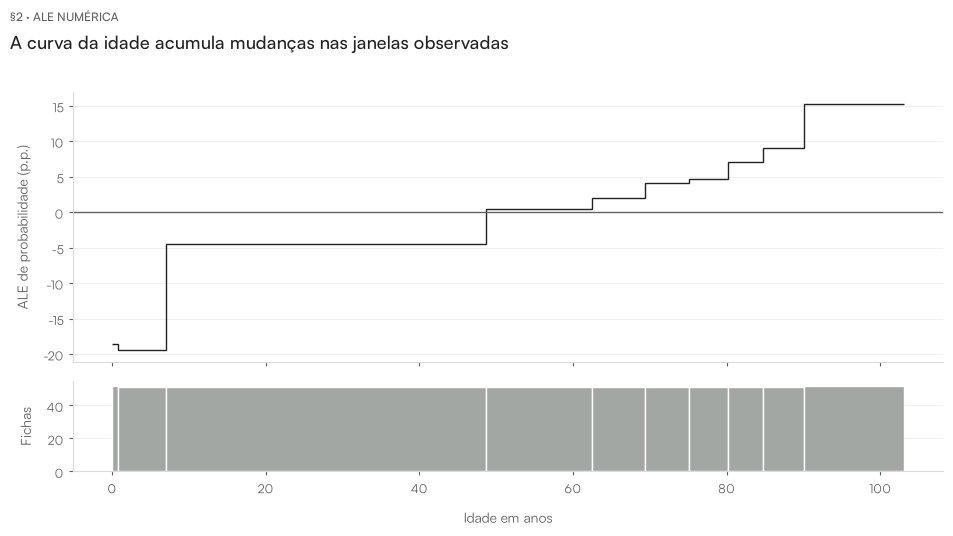

In [4]:
print(inspect.getsource(G.ale_numerica))
ale, atribuida = G.ale_numerica(prever, xp, "idade_anos", bins=10)
print(SP.tabela(ale, casas=6))
print("Média ALE atribuída às fichas:", SP.pt_sig(atribuida.mean(), 4))
print("Amplitude ALE, p.p.:", SP.pt(100 * np.ptp(ale["ale"]), 4))
assert abs(atribuida.mean()) < 1e-12
fig, axes = plt.subplots(
    2, 1, figsize=SP.SLOT, sharex=True, gridspec_kw={"height_ratios": [3, 1]}
)
axes[0].stairs(
    ale["ale"] * 100,
    np.r_[ale["esquerda"].iloc[0], ale["direita"]],
    baseline=None,
    color=SP.ESCURO,
)
axes[0].axhline(0, color=SP.CINZA, linewidth=1)
axes[0].set(ylabel="ALE de probabilidade (p.p.)")
axes[1].bar(
    (ale["esquerda"] + ale["direita"]) / 2,
    ale["n"],
    width=ale["direita"] - ale["esquerda"],
    color=SP.CINZA_CLARO,
    edgecolor=SP.PAPEL,
)
axes[1].set(xlabel="Idade em anos", ylabel="Fichas")
SP.titulo(
    fig, "A curva da idade acumula mudanças nas janelas observadas", "§2 · ALE numérica"
)
SP.salvar(fig, "ale-idade")
plt.show()

**O que olhar.**

- A tabela permite refazer cada acúmulo; a média ponderada impressa confere a centralização.
- O eixo mostra mudança de probabilidade em pontos percentuais, sem intercepto de risco absoluto.

## §3 — PDP e ALE usam ponderações diferentes

Comparamos as curvas nas mesmas bordas e centralizamos o PDP com as contagens dos intervalos. Essa escolha só alinha a apresentação: não converte a média marginal em diferenças condicionais.

Maior diferença entre as curvas centralizadas, p.p.: 0,7799
figura: figures_generated/ale-vs-pdp.png


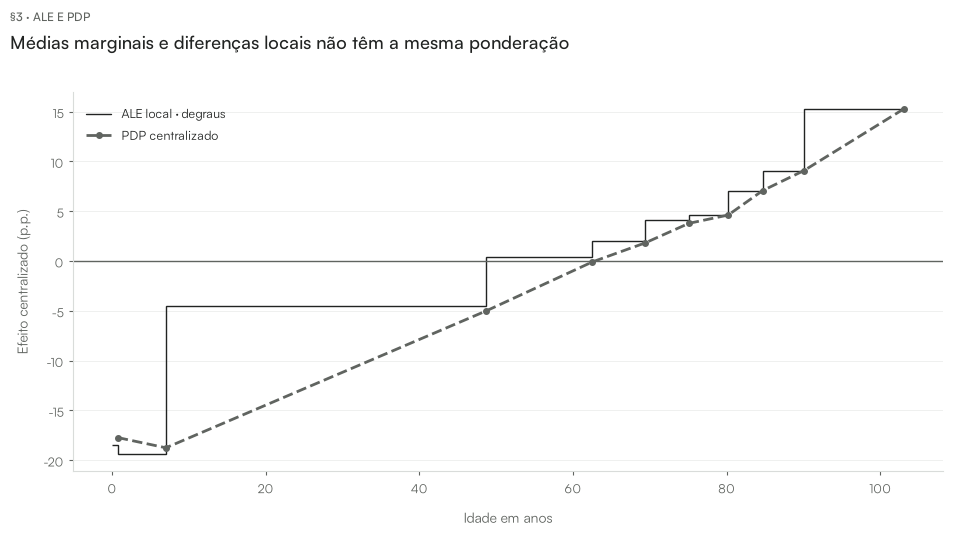

In [5]:
pdp = G.pd_empirica(prever, xp, pd.DataFrame({"idade_anos": ale["direita"]}))
pdp -= np.average(pdp, weights=ale["n"])
gap = np.max(np.abs(pdp - ale["ale"]))
print("Maior diferença entre as curvas centralizadas, p.p.:", SP.pt(100 * gap, 4))
fig, ax = plt.subplots(figsize=SP.SLOT)
ax.stairs(
    ale["ale"] * 100,
    np.r_[ale["esquerda"].iloc[0], ale["direita"]],
    baseline=None,
    label="ALE local · degraus",
    color=SP.ESCURO,
)
ax.plot(
    ale["direita"],
    pdp * 100,
    label="PDP centralizado",
    color=SP.CINZA,
    linestyle="--",
    marker="o",
    markersize=4,
)
ax.axhline(0, color=SP.CINZA, linewidth=1)
ax.set(xlabel="Idade em anos", ylabel="Efeito centralizado (p.p.)")
ax.legend()
SP.titulo(
    fig,
    "Médias marginais e diferenças locais não têm a mesma ponderação",
    "§3 · ALE e PDP",
)
SP.salvar(fig, "ale-vs-pdp")
plt.show()

**O que olhar.**

- A distância impressa pertence a esta discretização e ao painel, não a uma disputa por uma curva verdadeira.
- ALE também move uma entrada mantendo as demais fixas; a janela local não garante plausibilidade clínica.

## §4 — Refinar os intervalos muda a resolução

Repetimos com diferentes orçamentos de intervalos e imprimimos as contagens mínimas. Quantis iguais são unidos. Não há ALE categórico aqui: impor uma ordem às categorias de sintomas exigiria outra definição.

intervalos pedidos efetivos menor n amplitude p.p.    média
                 5        5     102      34,718339 0,000000
                10       10      51      34,676392 0,000000
                20       20      25      32,821743 0,000000
figura: figures_generated/ale-bins.png


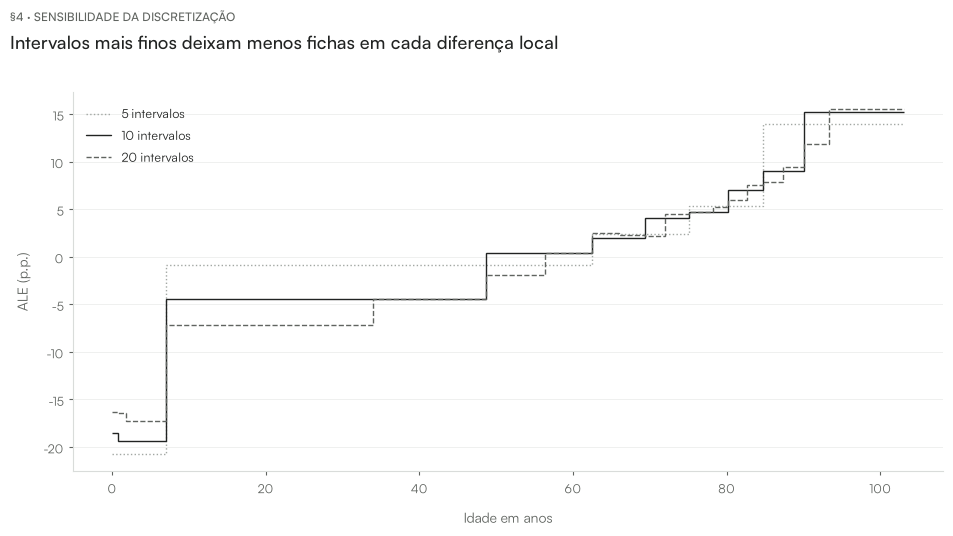

In [6]:
sens = []
fig, ax = plt.subplots(figsize=SP.SLOT)
for bins, color, estilo in zip(
    [5, 10, 20], [SP.CINZA_CLARO, SP.ESCURO, SP.CINZA], [":", "-", "--"]
):
    tab, assigned = G.ale_numerica(prever, xp, "idade_anos", bins=bins)
    sens.append(
        {
            "intervalos pedidos": bins,
            "efetivos": len(tab),
            "menor n": tab["n"].min(),
            "amplitude p.p.": 100 * np.ptp(tab["ale"]),
            "média": assigned.mean(),
        }
    )
    ax.stairs(
        100 * tab["ale"],
        np.r_[tab["esquerda"].iloc[0], tab["direita"]],
        baseline=None,
        label=f"{SP.pt_int(bins)} intervalos",
        color=color,
        linestyle=estilo,
    )

print(SP.tabela(pd.DataFrame(sens), casas=6))
ax.set(xlabel="Idade em anos", ylabel="ALE (p.p.)")
ax.legend()
SP.titulo(
    fig,
    "Intervalos mais finos deixam menos fichas em cada diferença local",
    "§4 · Sensibilidade da discretização",
)
SP.salvar(fig, "ale-bins")
plt.show()

**O que olhar.**

- Compare amplitude e menor contagem: refinar a grade não cria novas observações.
- O núcleo recusa valores ausentes e intervalos vazios; a idade desta base passa pelas condições explicitadas.

### O que o livro diz

O [capítulo de Molnar](https://christophm.github.io/interpretable-ml-book/ale.html) orienta o mecanismo e a leitura. ALE acumula diferenças locais e centraliza o resultado. A discretização e o suporte observado fazem parte da explicação. O caso SRAG acrescenta restrições do formulário, seleção hospitalar e deriva temporal. Nenhuma curva é uma estimativa do efeito de tratar ou modificar uma pessoa.

## §5 — Auditoria da base e da amostra de explicação

A referência é a amostra Gold commitada do projeto, não a extração bruta inteira do SIVEP-Gripe. Conferimos sua integridade e comparamos o painel com o teste temporal completo. As distribuições descritivas abaixo não demonstram representatividade populacional. O desfecho entra apenas nesta descrição posterior ao sorteio, nunca na construção das curvas.

O livro e o pacote foram inspecionados em revisões fixadas: [fonte do livro](https://github.com/christophM/interpretable-ml-book/tree/8f470c85e5ed4ebd69de74425cb9832f1bdc25eb) e [fonte de iml](https://github.com/giuseppec/iml/tree/4818c8f81dea2e76318857fbc3d50bc78cdd22f6). A avaliação distingue fórmula, configuração numérica, aplicação na base e alcance da interpretação. Não executamos o pacote R: as conferências de seu algoritmo são traduções explícitas para Python, identificadas nos internals.


In [7]:
from scipy.stats import ks_2samp

amostra_sha = hashlib.sha256(path.read_bytes()).hexdigest()
assert amostra_sha == "cb79c99338a5a7b3c125659aad148a73749e2695f2048c9481a20ab29e3ca918"
assert gold["gold_id"].is_unique
assert not set(gold.loc[tr, "gold_id"]) & set(teste["gold_id"])
linhas = []
for nome, base in [("Teste temporal", teste), ("Painel", painel), ("Fundo", fundo)]:
    xx, _, yy = M.design_matrix(base)
    linhas.append(
        {
            "referência": nome,
            "fichas": len(base),
            "óbitos observados": int(yy.sum()),
            "fração óbito": yy.mean(),
            "previsão média": prever(xx).mean(),
            "idade p10": base["idade_anos"].quantile(0.1),
            "idade mediana": base["idade_anos"].median(),
            "idade p90": base["idade_anos"].quantile(0.9),
            "saturação sim": (base["saturacao"] == "sim").mean(),
            "saturação desconhecida": (base["saturacao"] == "desconhecido").mean(),
            "células ausentes em X": int(xx.isna().sum().sum()),
            "fora da coorte": int(M.gate_reasons(base)["fora_coorte"].sum()),
        }
    )
print(SP.tabela(pd.DataFrame(linhas), casas=6))
print("Identificadores únicos e treino/teste sem sobreposição:", True)
print(
    "Distância KS descritiva da idade, painel vs teste:",
    SP.pt(ks_2samp(painel["idade_anos"], teste["idade_anos"]).statistic, 6),
)
cat_p = painel["saturacao"].value_counts(normalize=True)
cat_t = teste["saturacao"].value_counts(normalize=True)
print(
    "Variação total da saturação, painel vs teste:",
    SP.pt(0.5 * (cat_p - cat_t).abs().sum(), 6),
)
print("Livro: revisão 8f470c85e5ed4ebd69de74425cb9832f1bdc25eb")
print("iml: versão 0.11.4, revisão 4818c8f81dea2e76318857fbc3d50bc78cdd22f6")
print("Execução nativa em R nesta auditoria:", False)

    referência fichas óbitos observados fração óbito previsão média idade p10 idade mediana idade p90 saturação sim saturação desconhecida células ausentes em X fora da coorte
Teste temporal 16.142             2.945     0,182443       0,215373  0,583436     68,555786 89,472961      0,616528               0,138397                     0              0
        Painel    512                94     0,183594       0,219387  0,760575     69,393570 90,069270      0,640625               0,134766                     0              0
         Fundo    256                51     0,199219       0,224372  0,947296     70,046539 90,754280      0,660156               0,140625                     0              0
Identificadores únicos e treino/teste sem sobreposição: True
Distância KS descritiva da idade, painel vs teste: 0,040275
Variação total da saturação, painel vs teste: 0,024097
Livro: revisão 8f470c85e5ed4ebd69de74425cb9832f1bdc25eb
iml: versão 0.11.4, revisão 4818c8f81dea2e76318857fbc3d50bc78cdd

## Fechamento — A medida só faz sentido com seu condicionamento

Identifique preditor, escala, fundo, grade e regra de ponderação antes de interpretar a figura. Uma reconstrução algébrica ou um controle sintético valida o cálculo sob suas hipóteses; não valida as combinações artificiais como pacientes plausíveis.

In [8]:
pd.testing.assert_frame_equal(xf, original_xf)
assert bytes(model.get_booster().save_raw()) == model_bytes
print("Matriz de fundo e preditor permaneceram intactos:", True)

Matriz de fundo e preditor permaneceram intactos: True


## Referências

Molnar — [cap. 20](https://christophm.github.io/interpretable-ml-book/ale.html). Referências completas e configuração no [README](../README.md).